# Functional enrichment

Test coordinated condition-associated signals across the sequenced RNA pools.


In [1]:
from pathlib import Path
from time import perf_counter

import gseapy as gp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from scipy.stats import hypergeom
from statsmodels.stats.multitest import multipletests

ALPHA = 0.05
MIN_SET_SIZE = 10
MAX_SET_SIZE = 500
PERMUTATIONS = 1_000
THREADS = 8
RANDOM_SEED = 1077
EXPECTED_GSEAPY_VERSION = '1.3.1'
ANALYSES = {
    'input': 'inputDifferentialExpression.tsv',
    'monosome': 'monosomeDifferentialAbundance.tsv',
    'polysome': 'polysomeDifferentialAbundance.tsv',
    'redistribution': 'polysomeMonosome.tsv',
}
ANALYSIS_LABELS = {
    'input': 'Input RNA',
    'monosome': 'Monosome-associated RNA',
    'polysome': 'Polysome-associated RNA',
    'redistribution': 'Polysome–monosome redistribution',
}
COLLECTION_LABELS = {
    'goBiologicalProcess': 'GO BP',
    'goCellularComponent': 'GO CC',
    'goMolecularFunction': 'GO MF',
    'synGO': 'SynGO',
    'fuAsd': 'Fu ASD',
}
DIRECTION_LABELS = {
    ('input', 'positive'): 'Higher in ASD',
    ('input', 'negative'): 'Lower in ASD',
    ('monosome', 'positive'): 'Higher monosome-associated abundance in ASD',
    ('monosome', 'negative'): 'Lower monosome-associated abundance in ASD',
    ('polysome', 'positive'): 'Higher polysome-associated abundance in ASD',
    ('polysome', 'negative'): 'Lower polysome-associated abundance in ASD',
    ('redistribution', 'positive'): 'Higher polysome–monosome ratio in ASD',
    ('redistribution', 'negative'): 'Lower polysome–monosome ratio in ASD',
}

sns.set_theme(style = 'ticks', context = 'notebook')


In [2]:
# Locate the project and load tested gene-level results.


def find_root(start: Path) -> Path:
    for path in (start, *start.parents):
        if (path / 'data').is_dir():
            return path
    raise FileNotFoundError('Could not find the project data directory.')


ROOT = find_root(Path.cwd().resolve())
DATA_DIR = ROOT / 'data'
GENE_SET_DIR = DATA_DIR / 'geneSets'
RESULTS_DIR = ROOT / 'results'

metadata = pd.read_csv(DATA_DIR / 'metadata.tsv', sep = '\t', dtype = 'string')
sample_ids = metadata['sampleId'].tolist()
raw_results = {
    analysis: pd.read_csv(RESULTS_DIR / filename, sep = '\t')
    for analysis, filename in ANALYSES.items()
}
manifest = pd.read_csv(GENE_SET_DIR / 'geneSetManifest.tsv', sep = '\t')

if gp.__version__ != EXPECTED_GSEAPY_VERSION:
    raise RuntimeError(
        f'Expected GSEApy {EXPECTED_GSEAPY_VERSION}, found {gp.__version__}.'
    )
if set(manifest['collection']) != set(COLLECTION_LABELS):
    raise ValueError('The pinned gene-set manifest is incomplete.')

display(manifest)


,collection,fileName,sourceLibrary,sourceTerms,terms,retrievedDate,sourceUrl
0,goBiologicalProcess,goBiologicalProcess2026.gmt,GO_Biological_Process_2026,all,5952,2026-08-27,https://maayanlab.cloud/Enrichr/
1,goCellularComponent,goCellularComponent2026.gmt,GO_Cellular_Component_2026,all,506,2026-08-27,https://maayanlab.cloud/Enrichr/
2,goMolecularFunction,goMolecularFunction2026.gmt,GO_Molecular_Function_2026,all,1394,2026-08-27,https://maayanlab.cloud/Enrichr/
3,synGO,synGO2024.gmt,SynGO_2024,all,134,2026-08-27,https://maayanlab.cloud/Enrichr/
4,fuAsd,fuAsd2022.gmt,Fu et al. 2022 Supplementary Table 11,ASD72;ASD185,2,2026-09-04,https://doi.org/10.1038/s41588-022-01104-0


In [3]:
# Map Ensembl results to one deterministic record per gene symbol.


def prepare_results(table: pd.DataFrame):
    required = {
        'geneId',
        'geneName',
        'baseMean',
        'log2FoldChange',
        'statistic',
        'adjustedPValue',
    }
    missing = required.difference(table.columns)
    if missing:
        raise ValueError(f'Results are missing columns: {sorted(missing)}')
    if table['geneId'].isna().any() or not table['geneId'].is_unique:
        raise ValueError('Gene identifiers must be complete and unique.')

    mapped = table.copy()
    mapped['geneSymbol'] = (
        mapped['geneName'].astype('string').str.strip().str.upper()
    )
    valid = (
        mapped['geneSymbol'].notna()
        & mapped['geneSymbol'].ne('')
        & ~mapped['geneSymbol'].str.startswith('ENSG')
        & np.isfinite(mapped['statistic'])
        & np.isfinite(mapped['baseMean'])
    )
    mapped = mapped.loc[valid].copy()
    duplicated = mapped['geneSymbol'].duplicated(keep = False)
    mapped = mapped.sort_values(
        ['baseMean', 'geneId'],
        ascending = [False, True],
    )
    collapsed = mapped.drop_duplicates('geneSymbol', keep = 'first')
    collapsed = collapsed.set_index('geneSymbol', drop = False)
    summary = {
        'testedGenes': len(table),
        'mappedRows': len(mapped),
        'duplicateSymbolRows': int(duplicated.sum()),
        'rankedGenes': len(collapsed),
        'fdrGenesBeforeMapping': int(table['adjustedPValue'].lt(ALPHA).sum()),
        'fdrGenesAfterMapping': int(
            collapsed['adjustedPValue'].lt(ALPHA).sum()
        ),
    }
    return collapsed, summary


analysis_tables = {}
mapping_records = []

for analysis, table in raw_results.items():
    analysis_tables[analysis], summary = prepare_results(table)
    mapping_records.append({'analysis': analysis, **summary})

mapping_summary = pd.DataFrame(mapping_records)
display(mapping_summary)


,analysis,testedGenes,mappedRows,duplicateSymbolRows,rankedGenes,fdrGenesBeforeMapping,fdrGenesAfterMapping
0,input,21556,17803,82,17762,305,253
1,monosome,21888,17774,66,17741,192,165
2,polysome,21256,17613,70,17578,204,177
3,redistribution,20470,17189,58,17160,22,20


In [4]:
# Load and validate locally pinned gene-set collections.

gene_sets = {}
collection_records = []

for row in manifest.itertuples(index = False):
    path = GENE_SET_DIR / row.fileName
    if not path.is_file():
        raise FileNotFoundError(f'Missing pinned gene-set file: {path.name}')

    collection = gp.read_gmt(str(path))
    collection = {
        str(term): sorted({str(gene).upper() for gene in genes})
        for term, genes in collection.items()
    }
    if len(collection) != row.terms:
        raise ValueError(f'Term count does not match the manifest: {path.name}')
    if any(not genes for genes in collection.values()):
        raise ValueError(f'Empty gene set found in {path.name}.')

    gene_sets[row.collection] = collection

for analysis, table in analysis_tables.items():
    universe = set(table.index)
    for collection, terms in gene_sets.items():
        sizes = pd.Series({
            term: len(universe.intersection(genes))
            for term, genes in terms.items()
        })
        eligible = sizes.between(MIN_SET_SIZE, MAX_SET_SIZE)
        collection_records.append({
            'analysis': analysis,
            'collection': collection,
            'universeGenes': len(universe),
            'availableTerms': len(terms),
            'eligibleTerms': int(eligible.sum()),
            'minimumSetSize': MIN_SET_SIZE,
            'maximumSetSize': MAX_SET_SIZE,
        })

collection_summary = pd.DataFrame(collection_records)

if collection_summary['eligibleTerms'].eq(0).any():
    raise ValueError('At least one analysis-collection pair has no eligible terms.')

display(collection_summary)


,analysis,collection,universeGenes,availableTerms,eligibleTerms,minimumSetSize,maximumSetSize
0,input,goBiologicalProcess,17762,5952,3350,10,500
1,input,goCellularComponent,17762,506,314,10,500
2,input,goMolecularFunction,17762,1394,665,10,500
3,input,synGO,17762,134,78,10,500
4,input,fuAsd,17762,2,2,10,500
5,monosome,goBiologicalProcess,17741,5952,3342,10,500
6,monosome,goCellularComponent,17741,506,314,10,500
7,monosome,goMolecularFunction,17741,1394,664,10,500
8,monosome,synGO,17741,134,78,10,500
9,monosome,fuAsd,17741,2,2,10,500


In [5]:
# Run primary preranked enrichment with signed Wald statistics.
# Each prespecified collection is an independent GSEA multiple-testing family.


def run_prerank(
    analysis: str,
    table: pd.DataFrame,
    collection: str,
    terms: dict[str, list[str]],
):
    ranking = table[['geneSymbol', 'statistic']].reset_index(drop = True)
    ranking = ranking.sort_values(
        ['statistic', 'geneSymbol'],
        ascending = [False, True],
    )
    if ranking['geneSymbol'].duplicated().any():
        raise ValueError('Ranked gene symbols must be unique.')
    if ranking['statistic'].duplicated().any():
        raise ValueError('Ranked statistics contain unresolved ties.')

    result = gp.prerank(
        rnk = ranking,
        gene_sets = terms,
        min_size = MIN_SET_SIZE,
        max_size = MAX_SET_SIZE,
        permutation_num = PERMUTATIONS,
        weight = 1,
        ascending = False,
        threads = THREADS,
        outdir = None,
        no_plot = True,
        seed = RANDOM_SEED,
        verbose = False,
    )
    frame = result.res2d.rename(columns = {
        'Term': 'term',
        'ES': 'enrichmentScore',
        'NES': 'normalizedEnrichmentScore',
        'NOM p-val': 'pValue',
        'FDR q-val': 'adjustedPValue',
        'FWER p-val': 'familyWisePValue',
        'Lead_genes': 'leadingEdgeGenes',
    }).copy()
    tags = frame['Tag %'].str.split('/', expand = True).astype('int64')
    minimum_p = 1 / (PERMUTATIONS + 1)

    frame.insert(0, 'analysis', analysis)
    frame.insert(1, 'collection', collection)
    frame['direction'] = np.where(
        frame['normalizedEnrichmentScore'].gt(0),
        'positive',
        'negative',
    )
    frame['directionLabel'] = [
        DIRECTION_LABELS[(analysis, direction)]
        for direction in frame['direction']
    ]
    frame['leadingEdgeGenesCount'] = tags[0]
    frame['geneSetSize'] = tags[1]
    frame['leadingEdgeFraction'] = (
        frame['leadingEdgeGenesCount'] / frame['geneSetSize']
    )
    frame['rankAtPeakFraction'] = (
        frame['Gene %'].str.removesuffix('%').astype('float64') / 100
    )
    frame['pValue'] = frame['pValue'].astype('float64').clip(lower = minimum_p)
    frame['adjustedPValue'] = (
        frame['adjustedPValue'].astype('float64').clip(lower = minimum_p)
    )
    frame['familyWisePValue'] = (
        frame['familyWisePValue'].astype('float64').clip(lower = minimum_p)
    )
    frame['permutations'] = PERMUTATIONS
    frame['threads'] = THREADS
    return frame[[
        'analysis',
        'collection',
        'term',
        'direction',
        'directionLabel',
        'geneSetSize',
        'enrichmentScore',
        'normalizedEnrichmentScore',
        'pValue',
        'adjustedPValue',
        'familyWisePValue',
        'leadingEdgeGenesCount',
        'leadingEdgeFraction',
        'rankAtPeakFraction',
        'leadingEdgeGenes',
        'permutations',
        'threads',
    ]]


ranked_results = {}
ranked_timing_records = []


def run_ranked_cell(analysis: str, collection: str):
    start = perf_counter()
    frame = run_prerank(
        analysis,
        analysis_tables[analysis],
        collection,
        gene_sets[collection],
    )
    seconds = perf_counter() - start
    ranked_results[(analysis, collection)] = frame
    ranked_timing_records.append({
        'analysis': analysis,
        'collection': collection,
        'testedTerms': len(frame),
        'fdrTerms': int(frame['adjustedPValue'].lt(ALPHA).sum()),
        'seconds': seconds,
        'permutations': PERMUTATIONS,
        'threads': THREADS,
    })
    display(pd.DataFrame([ranked_timing_records[-1]]))
    display(
        frame.sort_values(['adjustedPValue', 'pValue'])[[
            'term',
            'direction',
            'normalizedEnrichmentScore',
            'pValue',
            'adjustedPValue',
            'leadingEdgeGenes',
        ]].head(10)
    )


In [6]:
# Run input Fu ASD-gene enrichment.

run_ranked_cell('input', 'fuAsd')


,analysis,collection,testedTerms,fdrTerms,seconds,permutations,threads
0,input,fuAsd,2,0,0.769577,1000,8


,term,direction,normalizedEnrichmentScore,pValue,adjustedPValue,leadingEdgeGenes
0,Fu ASD FDR <= 0.001,positive,0.825606,0.784062,0.837116,PLXNA1;KCNMA1;DSCAM;DEAF1;SHANK3;SPAST;FOXP1;K...
1,Fu ASD FDR <= 0.05,negative,-0.743586,0.976562,0.941647,SLC6A2;DNMT3A;CELF1;CYFIP2;ITPR3;CSNK2A1;KPNA1...


In [7]:
# Run input SynGO enrichment.

run_ranked_cell('input', 'synGO')


,analysis,collection,testedTerms,fdrTerms,seconds,permutations,threads
0,input,synGO,78,0,3.236643,1000,8


,term,direction,normalizedEnrichmentScore,pValue,adjustedPValue,leadingEdgeGenes
7,Translation At Postsynapse (GO:0140242) BP,positive,1.570753,0.019370,0.161751,RPS26;RPL9;UBA52;RPL29;RPL37A;RPL38;RPL36AL;RP...
6,Synaptic Vesicle Proton Loading (GO:0097401) BP,positive,1.589816,0.039823,0.161941,ATP6V0C;ATP6AP1;ATP6V0E2;ATP6V0D1;ATP6V1F;ATP6...
5,Regulation Of Postsynaptic Neurotransmitter Re...,positive,1.595625,0.026846,0.182302,NPTX2;NPTXR;NOTCH1;CACNG7;DLGAP2;CACNG4;NRXN2;...
4,Synapse Adhesion Between Pre- And Post-Synapse...,positive,1.619631,0.016018,0.183760,NLGN1;IL1RAP;FLRT3;PCDH17;CDH6;LRFN3;EPHA3;CDH...
3,Integral Component Of Postsynaptic Specializat...,positive,1.646548,0.022113,0.186279,CHRNA1;NLGN1;LRFN3;EPHA7;GABRA5;NLGN4X;NLGN4Y;...
2,Presynaptic Ribosome CC,positive,1.677736,0.009547,0.190478,RPS26;RPL9;UBA52;RPL29;RPL37A;RPL38;RPL36AL;RP...
1,Translation At Presynapse (GO:0140236) BP,positive,1.685187,0.009547,0.267155,RPS26;RPL9;UBA52;RPL29;RPL37A;RPL38;RPL36AL;RP...
0,Postsynaptic Ribosome CC,positive,1.757767,0.000999,0.289031,RPS26;RPL9;RPS18;UBA52;RPL29;RPL37A;RPL38;RPL3...
10,Presynapse Assembly (GO:0099054) BP,positive,1.441257,0.092760,0.312896,CNTN5;FZD5;DVL1;RAPH1;EFNB2;PTPRS;PTPRD
15,Transmitter-Gated IC Activity Involved In Regu...,positive,1.334801,0.113300,0.387142,CHRNA1;GRIN2A;GRIA4;GABRA5;GRIK2;GRIK1;GABRR2;...


In [8]:
# Run input GO Cellular Component enrichment.

run_ranked_cell('input', 'goCellularComponent')


,analysis,collection,testedTerms,fdrTerms,seconds,permutations,threads
0,input,goCellularComponent,314,0,11.348638,1000,8


,term,direction,normalizedEnrichmentScore,pValue,adjustedPValue,leadingEdgeGenes
14,90S Preribosome (GO:0030686),negative,-1.639946,0.040590,0.207028,NOP9;HEATR1;NOC4L;TBL3;UTP20;BMS1;TSR1;NOC2L;KRI1
0,Cytoplasmic Side of Lysosomal Membrane (GO:009...,positive,1.862540,0.004348,0.209931,LITAF;BORCS7;BLOC1S2;BORCS8;BLOC1S1;SNAPIN;CDIP1
8,Pigment Granule Membrane (GO:0090741),negative,-1.658789,0.012844,0.217569,TH;ABCB6;RAB38;RAB32;TPCN2
9,Chitosome (GO:0045009),negative,-1.658789,0.012844,0.217569,TH;ABCB6;RAB38;RAB32;TPCN2
10,Melanosome Membrane (GO:0033162),negative,-1.658789,0.012844,0.217569,TH;ABCB6;RAB38;RAB32;TPCN2
13,U2-type Precatalytic Spliceosome (GO:0071005),negative,-1.641711,0.008651,0.226402,SNRNP200;EFTUD2;SART1;SNRPB2;SF3A3;SF3B1;SF3B3...
17,Platelet Dense Tubular Network (GO:0031094),negative,-1.603814,0.033088,0.236582,ITPR1;ATP2A3;ITPR3;IRAG1;EHD1;ATP2A1
16,"Preribosome, Large Subunit Precursor (GO:0030687)",negative,-1.607535,0.031250,0.250294,FTSJ3;WDR12;NSA2;NOC2L;PPAN;WDR74;PES1;NIP7;ZN...
3,Supramolecular Fiber (GO:0099512),negative,-1.742777,0.000999,0.262018,DCN;FBLN1;FBN1;CTPS2;FN1;MYH3;CTPS1;MYH11;COL1...
19,"Preribosome, Small Subunit Precursor (GO:0030688)",negative,-1.575285,0.030361,0.275394,NOP9;NOC4L;UTP20;BYSL;RIOK1;NOP14;NOB1;RIOK2


In [9]:
# Run input GO Molecular Function enrichment.

run_ranked_cell('input', 'goMolecularFunction')


,analysis,collection,testedTerms,fdrTerms,seconds,permutations,threads
0,input,goMolecularFunction,665,1,29.95233,1000,8


,term,direction,normalizedEnrichmentScore,pValue,adjustedPValue,leadingEdgeGenes
0,Single-stranded DNA Binding (GO:0003697),negative,-2.087275,0.000999,0.013015,POU4F1;MCM9;DDX11;FUBP1;MCM5;MCM4;MCM6;TDP1;MC...
1,Aminoacyl-tRNA Ligase Activity (GO:0004812),negative,-1.983403,0.000999,0.056942,VARS2;EARS2;LARS2;FARSB;SARS2;AARS1;QARS1;KARS...
3,Estrogen Response Element Binding (GO:0034056),positive,1.929988,0.002179,0.124024,ESRRB;ESRRG;NR3C1
14,Single-stranded DNA Helicase Activity (GO:0017...,negative,-1.763248,0.003914,0.206318,MCM9;MCM5;MCM4;MCM6;MCM3;CHTF18;MCM7;MCM2;DHX9...
7,Histone H3 Demethylase Activity (GO:0141052),negative,-1.811197,0.005059,0.219960,KDM5D;KDM4C;UTY;RIOX1;PHF8;KDM1A;KDM3B;KDM5B;J...
11,CAMP Response Element Binding Protein Binding ...,positive,1.781190,0.010288,0.222469,SIK1;CREB3;DDIT3;CREM;ATF4
2,Ubiquitin Ligase Inhibitor Activity (GO:1990948),positive,1.934981,0.000999,0.228417,CDKN2A
13,Vitamin B6 Binding (GO:0070279),negative,-1.764532,0.000999,0.229531,THNSL2;ACCS;GLDC;SHMT2;CTH;CBS;CISD1;PDXK
9,Alkali Metal Ion Binding (GO:0031420),negative,-1.785618,0.000999,0.243857,ATP1A2;CAPN3;KCNJ11;ADPRH;ATP1A1;SCN8A
12,3'-5' DNA Helicase Activity (GO:0043138),negative,-1.768048,0.001883,0.250856,MCM9;MCM5;MCM6;MCM2;RECQL5;RECQL;DHX9;ERCC3;BL...


In [10]:
# Run input GO Biological Process enrichment.

run_ranked_cell('input', 'goBiologicalProcess')


,analysis,collection,testedTerms,fdrTerms,seconds,permutations,threads
0,input,goBiologicalProcess,3350,0,167.504022,1000,8


,term,direction,normalizedEnrichmentScore,pValue,adjustedPValue,leadingEdgeGenes
14,Negative Regulation of Cellular Senescence (GO...,negative,-1.913133,0.000999,0.119249,TBX2;TERT;CDK6;TWIST1
11,ADP Catabolic Process (GO:0046032),negative,-1.923295,0.001786,0.121994,GCK;ALDOB;HK2;PGK1;LDHA;GPI;ENO1;ENO3;PKM;PFKM...
12,Glycolytic Process (GO:0006096),negative,-1.923295,0.001786,0.121994,GCK;ALDOB;HK2;PGK1;LDHA;GPI;ENO1;ENO3;PKM;PFKM...
13,Pyridine Nucleotide Catabolic Process (GO:0019...,negative,-1.914555,0.000999,0.127656,GCK;ALDOB;HK2;PGK1;LDHA;GPI;ENO1;ENO3;PKM;PFKM...
9,Canonical Glycolysis (GO:0061621),negative,-1.929923,0.001866,0.139882,GCK;ALDOB;HK2;PGK1;GPI;ENO1;ENO3;PKM;PFKM;ALDO...
10,Glucose Catabolic Process to Pyruvate (GO:0061...,negative,-1.929923,0.001866,0.139882,GCK;ALDOB;HK2;PGK1;GPI;ENO1;ENO3;PKM;PFKM;ALDO...
16,Negative Regulation of Extrinsic Apoptotic Sig...,negative,-1.883426,0.000999,0.154864,GDNF;EYA4;EYA1;UNC5B;HSPA1A;HSPA1B;EYA2;NRG1;TERT
17,Negative Regulation of Signal Transduction in ...,negative,-1.883426,0.000999,0.154864,GDNF;EYA4;EYA1;UNC5B;HSPA1A;HSPA1B;EYA2;NRG1;TERT
18,Regulation of DNA-templated DNA Replication In...,negative,-1.876822,0.000999,0.157717,MCM5;MCM4;MCM6;MCM3;CUL4A;MCM7;MCM2;DTL;CDT1;DDB1
19,Carbohydrate Catabolic Process (GO:0016052),negative,-1.872705,0.001761,0.157769,GCK;ALDOB;MAN2C1;NAGA;HK2;PGK1;LDHA;GPI;ENO1;E...


In [11]:
# Run monosome Fu ASD-gene enrichment.

run_ranked_cell('monosome', 'fuAsd')


,analysis,collection,testedTerms,fdrTerms,seconds,permutations,threads
0,monosome,fuAsd,2,2,0.756318,1000,8


,term,direction,normalizedEnrichmentScore,pValue,adjustedPValue,leadingEdgeGenes
0,Fu ASD FDR <= 0.001,positive,1.912438,0.000999,0.000999,ASH1L;KMT2C;ZBTB20;PLXNA1;ANKRD11;KCNMA1;DSCAM...
1,Fu ASD FDR <= 0.05,positive,1.680935,0.000999,0.001570,RAB11FIP4;ASH1L;NAV3;KMT2C;TSC1;ATG9B;PAX5;ZBT...


In [12]:
# Run monosome SynGO enrichment.

run_ranked_cell('monosome', 'synGO')


,analysis,collection,testedTerms,fdrTerms,seconds,permutations,threads
0,monosome,synGO,78,2,5.322184,1000,8


,term,direction,normalizedEnrichmentScore,pValue,adjustedPValue,leadingEdgeGenes
0,Synaptic Vesicle Exocytosis (GO:0016079) BP,positive,2.004234,0.000999,0.011562,UNC13A;MCTP1;VAMP7;STX3
1,Anchored Component Of Synaptic Vesicle Membran...,negative,-1.926615,0.000999,0.019311,RAB3C;RAB11B;RAB11A;RAB2A;RAB7A;RAB5A;RAB10;RA...
5,Neuronal Dense Core Vesicle (GO:0098992) CC,negative,-1.598565,0.027304,0.207837,TAC1;PLCB2;SST;PDYN;CACNA2D1
3,Extrinsic Component Of Synaptic Vesicle Membra...,negative,-1.624289,0.022184,0.222401,AMPH;GAPDH;SYN2;ATP6V1B1;SYN3;ATP6V1E1;DOC2A;T...
6,Synaptic Vesicle Proton Loading (GO:0097401) BP,negative,-1.550741,0.050611,0.245253,ATP6V1B1;ATP6AP2;ATP6V1E1;ATP6V0D1;ATP6V1B2;CL...
2,Presynaptic Endosome (GO:0098830) CC,negative,-1.631673,0.027829,0.312842,RAB11A;PIK3C3;RAB7A;RAB5A;RABGEF1;VAC14;CTSD
4,Integral Component Of Postsynaptic Specializat...,positive,1.607677,0.009780,0.353177,CHRNA1;NLGN4X;GABRB3;GABRA5;EPHA7;KCNB1;LRRTM2...
7,Postsynaptic Endocytic Zone (GO:0098843) CC,negative,-1.448763,0.074523,0.408111,AMPH;SH3GLB2;NRN1;PICK1;PICALM;CLTA
8,Anchored Component Of Postsynaptic Density Mem...,negative,-1.422977,0.083929,0.417674,MDGA1;IGSF21;LZTS1;ABHD17B
10,Integral Component Of Synaptic Membrane (GO:00...,negative,-1.376199,0.114638,0.480246,PHOX2A


In [13]:
# Run monosome GO Cellular Component enrichment.

run_ranked_cell('monosome', 'goCellularComponent')


,analysis,collection,testedTerms,fdrTerms,seconds,permutations,threads
0,monosome,goCellularComponent,314,15,19.79131,1000,8


,term,direction,normalizedEnrichmentScore,pValue,adjustedPValue,leadingEdgeGenes
0,Ficolin-1-rich Granule Lumen (GO:1904813),negative,-2.167205,0.000999,0.003701,CCT8;GSDMD;DBNL;C1ORF35;PGAM1;PSMB1;PSMC2;PSMD...
1,Azurophil Granule Lumen (GO:0035578),negative,-2.144472,0.000999,0.003701,NAPRT;ARSA;CCT8;CTSC;CYB5R3;TUBB;TUBB4B;TOLLIP...
3,Vesicle (GO:0031982),negative,-2.037556,0.000999,0.004627,ATP1A2;CBR1;TMEM163;CD9;BMP5;PCMT1;TUBB2A;SLC2...
2,Vacuolar Lumen (GO:0005775),negative,-2.071922,0.000999,0.005758,NAPRT;DCN;ARSA;CCT8;CTSC;SDC1;LGMN;CYB5R3;SNRN...
4,Secretory Granule Lumen (GO:0034774),negative,-1.984853,0.000999,0.008883,NAPRT;ISLR;ARSA;CCT8;FN1;SELENOP;IGF2;GSDMD;CT...
6,U1 snRNP (GO:0005685),negative,-1.934096,0.001681,0.014629,LUC7L3;SNRPB2;SNRNP70;LUC7L;SNRPB;LUC7L2;SNRPA...
5,Ficolin-1-rich Granule (GO:0101002),negative,-1.936219,0.000999,0.016450,CCT8;GSDMD;DBNL;C1ORF35;PGAM1;PSMB1;PSMC2;PSMD...
7,Azurophil Granule (GO:0042582),negative,-1.907230,0.000999,0.017273,NAPRT;RAB3D;ARSA;CCT8;CTSC;CPNE1;CYB5R3;TUBB;T...
8,Cytoplasmic Vesicle Lumen (GO:0060205),negative,-1.893995,0.000999,0.017821,CCT8;DBNL;C1ORF35;PGAM1;PSMB1;PSMC2;PSMD11;ALD...
9,Multivesicular Body Membrane (GO:0032585),negative,-1.874470,0.003356,0.020111,CHMP2A;TMEM9;ABCB6;CHMP1B;LAPTM4B;CHMP4A;CHMP2...


In [14]:
# Run monosome GO Molecular Function enrichment.

run_ranked_cell('monosome', 'goMolecularFunction')


,analysis,collection,testedTerms,fdrTerms,seconds,permutations,threads
0,monosome,goMolecularFunction,664,10,40.4502,1000,8


,term,direction,normalizedEnrichmentScore,pValue,adjustedPValue,leadingEdgeGenes
0,"Oxidoreductase Activity, Acting on the CH-OH G...",negative,-2.272596,0.000999,0.000999,HSD17B13;CBR1;RDH10;AKR1C1;DHRS1;HSD17B8;ME3;B...
1,Alcohol Dehydrogenase (NADP+) Activity (GO:000...,negative,-2.248533,0.000999,0.000999,CBR1;DHRS3;RDH10;AKR1C1;DHRS1;AKR1B1;AKR7A3;DC...
2,Myosin V Binding (GO:0031489),negative,-2.012882,0.000999,0.023936,RAB3D;RAB3C;RAB11B;RAB6B;RAB11A;RAB10;RAB3B;RA...
4,Monocarboxylic Acid Binding (GO:0033293),negative,-1.955230,0.001792,0.036599,CRABP1;CYP26A1;CYP26B1;AKR1C1;STARD5;NR2F2;AKR...
3,"Steroid Dehydrogenase Act, Acting on the CH-OH...",negative,-1.969638,0.000999,0.037063,AKR1C1;HSD17B8;HSD17B2;HSD17B11;HSD17B10;AKR1C...
5,RNA Exonuclease Activity (GO:0004532),negative,-1.939725,0.000999,0.038800,EXOSC3;EXOSC2;EXOSC7;EXOSC8;DCPS;EXOSC4;EXOSC5...
9,Lipoprotein Particle Receptor Binding (GO:0070...,negative,-1.901639,0.000999,0.040190,APBB3;DNAJA1;DKK1;AP2M1;PCSK9;MESD;LANCL1;APOE...
8,RNA Nuclease Activity (GO:0004540),negative,-1.909082,0.000999,0.040923,ERN2;YBEY;RNASEH2A;RNASE4;EXOSC3;EXOSC2;EXOSC7...
6,Glutathione Transferase Activity (GO:0004364),negative,-1.921320,0.000999,0.044177,GSTO2;GSTM1;GSTM2;GSTM3;PTGES;GSTO1;GSTP1;LTC4...
7,Low-density Lipoprotein Particle Receptor Bind...,negative,-1.910687,0.001645,0.045025,APBB3;DNAJA1;DKK1;AP2M1;PCSK9;MESD;LANCL1;APOE...


In [15]:
# Run monosome GO Biological Process enrichment.

run_ranked_cell('monosome', 'goBiologicalProcess')


,analysis,collection,testedTerms,fdrTerms,seconds,permutations,threads
0,monosome,goBiologicalProcess,3342,46,201.342646,1000,8


,term,direction,normalizedEnrichmentScore,pValue,adjustedPValue,leadingEdgeGenes
0,Pyruvate Metabolic Process (GO:0006090),negative,-2.408510,0.000999,0.000999,LDHA;PDHA1;PGAM2;GCK;ME3;TPI1;PGK1;ALDOC;ENO1;...
1,Glucose Metabolic Process (GO:0006006),negative,-2.357564,0.000999,0.000999,TFAP2B;KCNJ11;TKTL1;PGAM2;GCK;PGAM1;TPI1;PGK1;...
2,Carbohydrate Catabolic Process (GO:0016052),negative,-2.277831,0.000999,0.000999,LDHA;PGAM2;GCK;NAGA;TPI1;PGK1;ALDOC;ENO1;PKM;M...
3,Glycolytic Process Through Glucose-6-Phosphate...,negative,-2.260765,0.000999,0.000999,PGAM2;GCK;PGAM1;TPI1;PGK1;ALDOC;ENO1;PKM;GPI;G...
5,Hexose Biosynthetic Process (GO:0019319),negative,-2.247242,0.000999,0.000999,PGAM2;PGAM1;AKR1B1;TPI1;PGK1;RBP4;ALDOC;ENO1;S...
6,Glucose Catabolic Process to Pyruvate (GO:0061...,negative,-2.244484,0.000999,0.000999,PGAM2;GCK;PGAM1;TPI1;PGK1;ALDOC;ENO1;PKM;GPI;G...
7,Canonical Glycolysis (GO:0061621),negative,-2.244484,0.000999,0.000999,PGAM2;GCK;PGAM1;TPI1;PGK1;ALDOC;ENO1;PKM;GPI;G...
9,Response to Type I Interferon (GO:0034340),negative,-2.219341,0.000999,0.000999,PSMB3;PSMB2;PSMB6;PSMB1;PSMC2;PSMD11;PSMD12;PS...
10,ADP Catabolic Process (GO:0046032),negative,-2.206060,0.000999,0.000999,LDHA;PGAM2;GCK;TPI1;PGK1;ALDOC;ENO1;PKM;GPI;GA...
11,Glycolytic Process (GO:0006096),negative,-2.206060,0.000999,0.000999,LDHA;PGAM2;GCK;TPI1;PGK1;ALDOC;ENO1;PKM;GPI;GA...


In [16]:
# Run polysome Fu ASD-gene enrichment.

run_ranked_cell('polysome', 'fuAsd')


,analysis,collection,testedTerms,fdrTerms,seconds,permutations,threads
0,polysome,fuAsd,2,0,0.844709,1000,8


,term,direction,normalizedEnrichmentScore,pValue,adjustedPValue,leadingEdgeGenes
1,Fu ASD FDR <= 0.05,negative,-1.054774,0.347305,0.359968,EFTUD2;ZBTB20;NAA15;CHD8;DYNC1H1;ZMYND8;UBR5;G...
0,Fu ASD FDR <= 0.001,negative,-1.078686,0.328859,0.615506,ZBTB20;NAA15;CHD8;DYNC1H1;GIGYF1;CTNNB1;MED23;...


In [17]:
# Run polysome SynGO enrichment.

run_ranked_cell('polysome', 'synGO')


,analysis,collection,testedTerms,fdrTerms,seconds,permutations,threads
0,polysome,synGO,78,1,5.750065,1000,8


,term,direction,normalizedEnrichmentScore,pValue,adjustedPValue,leadingEdgeGenes
0,Postsynaptic Ribosome CC,negative,-1.885518,0.000999,0.048450,RPL5;RPL4;RPS11;RPL11;RPS8;RPSA;RPS24;RPS27;RP...
1,Modification Of Postsynaptic Actin Cytoskeleto...,positive,1.849390,0.002141,0.093711,CFL1;PFN1;PFN2;WASF3;WASF1;DIXDC1
3,Synaptic Vesicle Membrane (GO:0030672) CC,positive,1.697397,0.004396,0.120542,SH3GL2;ATG9A;GNAO1;ANXA5;PRKN;CLTB;CDK16;CLTA;...
2,Integral Component Of Postsynaptic Specializat...,positive,1.735109,0.002398,0.127951,CHRNA1;NLGN1;GABRA5;CHRNB2;KCND2;NLGN4X;GLRA2;...
6,Translation At Presynapse (GO:0140236) BP,negative,-1.640790,0.013514,0.132387,RPL5;RPL4;RPS11;RPL11;RPS24;RPS27;RPS10;RPL7;R...
5,Translation At Postsynapse (GO:0140242) BP,negative,-1.655884,0.011885,0.156400,RPL5;RPL4;RPS11;RPL11;RPS24;RPS27;RPS10;RPL7;R...
4,Presynaptic Ribosome CC,negative,-1.656630,0.008460,0.233324,RPL5;RPL4;RPS11;RPL11;RPS24;RPS27;RPS10;RPL7;R...
7,Synapse Adhesion Between Pre- And Post-Synapse...,positive,1.552046,0.029148,0.291944,IL1RAP;FLRT3;NLGN1;ELFN1;SLITRK2;EPHA3;CDH6;LR...
9,Integral Component Of Synaptic Vesicle Membran...,positive,1.490364,0.015190,0.293146,OPRK1;MAL2;TMEM230;ATP6V0C;SV2B;SYPL1;SLC17A5;...
8,Integral Component Of Postsynaptic Membrane (G...,positive,1.512022,0.005362,0.304920,GRM3;TACR1;SLC1A7;NELL2;OPRK1;FLRT3;FXYD6;ITGB...


In [18]:
# Run polysome GO Cellular Component enrichment.

run_ranked_cell('polysome', 'goCellularComponent')


,analysis,collection,testedTerms,fdrTerms,seconds,permutations,threads
0,polysome,goCellularComponent,314,31,20.495071,1000,8


,term,direction,normalizedEnrichmentScore,pValue,adjustedPValue,leadingEdgeGenes
0,U2-type Spliceosomal Complex (GO:0005684),negative,-2.552183,0.000999,0.000999,TFIP11;LUC7L3;SF3B1;CRNKL1;EFTUD2;PRPF3;SRRM2;...
2,Intermediate Filament (GO:0005882),negative,-2.104183,0.000999,0.001907,KRT8;PRPH;DSP;GPER1;PNN;PPL;NEFM;MICAL1;KRT18;...
3,Precatalytic Spliceosome (GO:0071011),negative,-2.088840,0.000999,0.001907,SF3B1;EFTUD2;PRPF3;SRRM2;SNRNP70;MFAP1;PRPF8;S...
5,Post-mRNA Release Spliceosomal Complex (GO:007...,negative,-2.056076,0.000999,0.002225,TFIP11;CRNKL1;XAB2;GCFC2;DHX15;CWF19L2;YJU2B;C...
4,CMG Complex (GO:0071162),negative,-2.073942,0.000999,0.002289,MCM5;MCM3;MCM4;MCM6;MCM2;MCM7
1,U2-type Precatalytic Spliceosome (GO:0071005),negative,-2.105651,0.000999,0.002861,SF3B1;EFTUD2;PRPF3;SRRM2;MFAP1;PRPF8;SNRNP200;...
8,Cytosolic Large Ribosomal Subunit (GO:0022625),negative,-2.022746,0.001692,0.003073,RPL3;RPL5;RPL41;RPL4;RPL36A;RPL11;RPL7A;RPL7;R...
7,U2-type Catalytic Step 2 Spliceosome (GO:0071007),negative,-2.023114,0.000999,0.003457,CRNKL1;EFTUD2;SRRM2;DHX8;PRPF8;XAB2;AQR;PLRG1;...
6,Supramolecular Fiber (GO:0099512),negative,-2.027299,0.000999,0.003815,DCN;COL6A2;MYH3;FBLN1;MYH7B;MFAP1;COL6A1;HSPG2...
10,Elastic Fiber (GO:0071953),negative,-1.988869,0.000999,0.004387,DCN;COL6A2;FBLN1;MFAP1;COL6A1;HSPG2;LTBP4;COL1...


In [19]:
# Run polysome GO Molecular Function enrichment.

run_ranked_cell('polysome', 'goMolecularFunction')


,analysis,collection,testedTerms,fdrTerms,seconds,permutations,threads
0,polysome,goMolecularFunction,661,5,42.92852,1000,8


,term,direction,normalizedEnrichmentScore,pValue,adjustedPValue,leadingEdgeGenes
0,Aminoacyl-tRNA Ligase Activity (GO:0004812),negative,-2.479967,0.000999,0.000999,EPRS1;VARS2;LARS1;AARS1;TARS1;QARS1;RARS1;FARS...
1,Single-stranded DNA Binding (GO:0003697),negative,-2.146637,0.000999,0.005021,POU4F1;ERCC5;MCM5;MSH2;FUBP1;BLM;MCM3;MCM4;MCM...
2,Telomeric Repeat DNA Binding (GO:0042162),negative,-2.075255,0.000999,0.009707,XRCC5;BLM;XRCC6;TELO2;HNRNPA2B1;ZBTB48;KDM1A;P...
4,Nucleosomal DNA Binding (GO:0031492),negative,-2.028492,0.000999,0.016318,H3C1;H1-4;H1-5;H1-2;CHD4;H1-3;HDAC2;VRK1;ACTL6...
8,Single-stranded DNA Helicase Activity (GO:0017...,negative,-1.937268,0.001852,0.048603,MCM5;MCM3;MCM4;MCM6;MCM2;CHTF18;DHX9;MCM7;DNA2
12,MRNA Binding (GO:0003729),negative,-1.903203,0.000999,0.053796,PUM3;LRPPRC;LUC7L3;SF3B1;FUBP1;KHDRBS3;SSB;ZNF...
10,5'-3' DNA Helicase Activity (GO:0043139),negative,-1.907764,0.003831,0.059750,DDX11;IGHMBP2;DNA2;ERCC2;ZGRF1;UPF1;TWNK
7,Metalloendopeptidase Inhibitor Activity (GO:00...,positive,1.948307,0.000999,0.061407,SPOCK2;SPOCK1;TIMP2;TIMP4;TIMP3
13,Protein-cysteine S-palmitoyltransferase Activi...,positive,1.896736,0.002299,0.063077,ZDHHC14;ZDHHC2;ZDHHC7;HHAT;ZDHHC9;ZDHHC24;GLUL...
14,SnoRNA Binding (GO:0030515),negative,-1.878594,0.000999,0.064896,UTP6;XRCC5;TBL3;UTP25;NOP58;DDX21;NOP56;PRKDC;...


In [20]:
# Run polysome GO Biological Process enrichment.

run_ranked_cell('polysome', 'goBiologicalProcess')


,analysis,collection,testedTerms,fdrTerms,seconds,permutations,threads
0,polysome,goBiologicalProcess,3347,110,213.211019,1000,8


,term,direction,normalizedEnrichmentScore,pValue,adjustedPValue,leadingEdgeGenes
0,"MRNA Splicing, via Spliceosome (GO:0000398)",negative,-2.532413,0.000999,0.000999,MTREX;TFIP11;SF3B1;CRNKL1;EFTUD2;DDX1;PPWD1;KI...
1,MRNA Processing (GO:0006397),negative,-2.494295,0.000999,0.000999,MTREX;TFIP11;SF3B1;TCERG1;CRNKL1;EFTUD2;SYMPK;...
2,"RNA Splicing, via Transesterification Reaction...",negative,-2.443638,0.000999,0.000999,MTREX;TFIP11;SF3B1;CRNKL1;EFTUD2;PPWD1;KIN;PNN...
3,TRNA Aminoacylation for Protein Translation (G...,negative,-2.429443,0.000999,0.000999,EPRS1;VARS2;LARS1;AARS1;TARS1;QARS1;RARS1;FARS...
4,RNA Processing (GO:0006396),negative,-2.418946,0.000999,0.000999,MTREX;DNTTIP2;TFIP11;LUC7L3;SF3B1;TCERG1;FUS;I...
5,DNA-templated DNA Replication (GO:0006261),negative,-2.316909,0.000999,0.000999,POLRMT;MCM5;MCM3;MCM4;WDHD1;BAZ1A;POLE;MCM2;RR...
6,Positive Regulation of Telomere Maintenance vi...,negative,-2.276822,0.000999,0.000999,ATR;CCT2;HSP90AA1;CCT8;HNRNPA2B1;CTNNB1;CCT4;C...
7,Maturation of LSU-rRNA Fm Tricistronic rRNA Tr...,negative,-2.247950,0.000999,0.000999,LAS1L;DDX18;FTSJ3;NOL9;TEX10;PES1;MDN1;PPAN;WD...
8,Ribosome Biogenesis (GO:0042254),negative,-2.246337,0.000999,0.000999,MTREX;DNTTIP2;EIF5B;UTP6;WDR75;NOL8;LAS1L;TBL3...
9,RRNA Processing (GO:0006364),negative,-2.227748,0.000999,0.000999,MTREX;DNTTIP2;UTP6;WDR75;NOL11;NOL8;LAS1L;TBL3...


In [21]:
# Run redistribution Fu ASD-gene enrichment.

run_ranked_cell('redistribution', 'fuAsd')


,analysis,collection,testedTerms,fdrTerms,seconds,permutations,threads
0,redistribution,fuAsd,2,2,0.832626,1000,8


,term,direction,normalizedEnrichmentScore,pValue,adjustedPValue,leadingEdgeGenes
0,Fu ASD FDR <= 0.001,negative,-2.336194,0.000999,0.000999,DYNC1H1;CHD8;ZBTB20;KMT2A;NAA15;ASH1L;ANK2;TCF...
1,Fu ASD FDR <= 0.05,negative,-2.077589,0.000999,0.000999,HECTD4;CHD3;DYNC1H1;CHD8;UBR5;ZBTB20;EFTUD2;KM...


In [22]:
# Run redistribution SynGO enrichment.

run_ranked_cell('redistribution', 'synGO')


,analysis,collection,testedTerms,fdrTerms,seconds,permutations,threads
0,redistribution,synGO,78,7,6.487778,1000,8


,term,direction,normalizedEnrichmentScore,pValue,adjustedPValue,leadingEdgeGenes
0,Anchored Component Of Synaptic Vesicle Membran...,positive,2.275598,0.000999,0.000999,RAB11B;RAB10;RAB7A;RAB5C;RAB2A;RAB35;RAB5A;DNA...
2,Integral Component Of Synaptic Vesicle Membran...,positive,2.127480,0.000999,0.001046,ATP6V0C;SLC32A1;STX6;SLC10A4;LAMP1;OPRK1;ATP6A...
1,Postsynaptic Ribosome CC,negative,-2.213167,0.000999,0.001861,RPS26;RPL4;RPL5;RPS24;RPS18;RPS27;RPL9;RPL27A;...
4,Presynaptic Ribosome CC,negative,-2.041449,0.000999,0.003723,RPS26;RPL4;RPL5;RPS24;RPS27;RPL9;RPL27A;RPL17;...
5,Translation At Presynapse (GO:0140236) BP,negative,-2.013846,0.002632,0.003955,RPS26;RPL4;RPL5;RPS24;RPS27;RPL9;RPL27A;RPL17;...
3,Translation At Postsynapse (GO:0140242) BP,negative,-2.060494,0.000999,0.005119,RPS26;EEF2;RPL4;RPL5;RPS24;RPS27;RPL9;RPL27A;R...
6,Synaptic Vesicle Membrane (GO:0030672) CC,positive,1.856600,0.001724,0.022666,PPT1;CLTA;ATG9A;ANP32E;GNB2;GNAO1;SNCA;TAFA4;A...
7,Anchored Component Of Presynaptic Membrane (GO...,positive,1.753486,0.003484,0.055183,MARCKSL1;RAC1;SNAP25;RGS7BP;GPC4;LSAMP
8,Postsynaptic Membrane (GO:0045211) CC,positive,1.729231,0.003546,0.058164,NTRK2;NAPEPLD;KCTD12;GNAO1;NRGN;SYT1;KCTD16;GNB5
9,Extrinsic Component Of Postsynaptic Density Me...,negative,-1.600246,0.039648,0.119685,SCRIB;AKAP9;PDE10A;RNF10;TIAM1;OLFM1;CNKSR2


In [23]:
# Run redistribution GO Cellular Component enrichment.

run_ranked_cell('redistribution', 'goCellularComponent')


,analysis,collection,testedTerms,fdrTerms,seconds,permutations,threads
0,redistribution,goCellularComponent,313,15,23.976019,1000,8


,term,direction,normalizedEnrichmentScore,pValue,adjustedPValue,leadingEdgeGenes
2,Multivesicular Body Membrane (GO:0032585),positive,2.108099,0.000999,0.002001,LAPTM4B;CHMP1B;CHMP2A;ATP13A2;TMEM9;CHMP1A;CD6...
4,Azurophil Granule Membrane (GO:0035577),positive,2.086201,0.000999,0.002334,RAB3D;SURF4;ARL8A;VAPA;ATP6V0C;RAB5C;LAMP1;DNA...
0,Recycling Endosome Membrane (GO:0055038),positive,2.152462,0.000999,0.003001,SLC31A1;SCAMP2;RAB11B;SCAMP4;NSG1;RAB35;RAB8A;...
6,Endoplasmic reticulum-Golgi Intermediate Compa...,positive,1.985545,0.000999,0.008253,VMA12;STX5;SEC22B;RAB1B;RAB43;MCFD2;PLPP3;TMED...
3,Intermediate Filament (GO:0005882),negative,-2.107835,0.000999,0.010993,DSP;FBF1;DST;PLEC;KRT8;MACF1;PPL;TLK2;NEFM;LMN...
1,Cytosolic Large Ribosomal Subunit (GO:0022625),negative,-2.115150,0.000999,0.019986,RPL4;RPL5;RPL3;RPL41;RPL9;RPL36A;RPL27A;RPL17;...
7,Cytosolic Small Ribosomal Subunit (GO:0022627),negative,-1.979464,0.000999,0.022984,RPS26;RPSA2;RPS24;RPS4Y1;RPS18;RPS27;DDX3X;DHX...
11,U2-type Spliceosomal Complex (GO:0005684),negative,-1.889418,0.000999,0.026857,SRRM2;SF3B1;PRPF8;EFTUD2;CRNKL1;DHX16;PRPF6;AQ...
10,Podosome (GO:0002102),negative,-1.901621,0.002415,0.027267,FERMT3;PLEC;SH3PXD2B;FLNA;LPXN;ADAM8;ERC1;FLII
5,Small Ribosomal Subunit (GO:0015935),negative,-1.988027,0.000999,0.027981,RPS26;RPSA2;RPS24;RPS4Y1;RPS18;RPS27;DDX3X;DHX...


In [24]:
# Run redistribution GO Molecular Function enrichment.

run_ranked_cell('redistribution', 'goMolecularFunction')


,analysis,collection,testedTerms,fdrTerms,seconds,permutations,threads
0,redistribution,goMolecularFunction,655,17,49.357496,1000,8


,term,direction,normalizedEnrichmentScore,pValue,adjustedPValue,leadingEdgeGenes
0,GDP Binding (GO:0019003),positive,2.257591,0.000999,0.002101,RAB11B;ARL8B;RAB10;RAB7A;RAB5C;RAB2A;RAB35;RAB...
1,Histone H3 Demethylase Activity (GO:0141052),negative,-2.167329,0.000999,0.007404,KDM5B;JMJD6;KDM1A;KDM3B;KDM5D;KDM3A;JMJD1C;PHF...
3,Nuclear Thyroid Hormone Receptor Binding (GO:0...,negative,-2.111327,0.000999,0.008947,NCOR1;BRD8;NSD1;MED12;TRIP12;GTF2B;THRAP3;NCOA...
4,"Oxidoreductase Activity, Acting on the CH-CH G...",positive,2.105074,0.000999,0.009454,DHRSX;DPYD;BDH2;SRD5A3;LBR;PTGR1;DHCR24;BLVRB;...
2,Histone Demethylase Activity (GO:0032452),negative,-2.122278,0.000999,0.012032,KDM5B;JMJD6;KDM1A;KDM5D;FBXL19;KDM5A;PHF2;KDM4...
5,Myosin V Binding (GO:0031489),positive,2.055328,0.000999,0.014707,RAB3D;RAB11B;RAB10;RAB8A;RAB11A;RAB3A;RAB6A;RA...
11,Guanyl Ribonucleotide Binding (GO:0032561),positive,2.001645,0.000999,0.014707,RAB11B;ARF3;ARL8A;RAB36;DIRAS2;ARF4;ARF1;ARL8B...
10,GTP Binding (GO:0005525),positive,2.011802,0.000999,0.015757,RAB11B;ARF3;ARL8A;RAB36;DIRAS2;ARF4;ARF1;ARL8B...
7,GTPase Activity (GO:0003924),positive,2.019144,0.000999,0.017596,RAB3D;RAB11B;ARF3;ARL8A;RAB36;DIRAS2;ARF4;ARF1...
9,Aminoacyl-tRNA Ligase Activity (GO:0004812),negative,-2.016181,0.000999,0.019591,EPRS1;RARS1;AARS1;TARS1;LARS1;RARS2;MARS1;VARS...


In [25]:
# Run redistribution GO Biological Process enrichment.

run_ranked_cell('redistribution', 'goBiologicalProcess')


,analysis,collection,testedTerms,fdrTerms,seconds,permutations,threads
0,redistribution,goBiologicalProcess,3313,13,239.566049,1000,8


,term,direction,normalizedEnrichmentScore,pValue,adjustedPValue,leadingEdgeGenes
1,Glutathione Metabolic Process (GO:0006749),positive,2.213759,0.000999,0.008974,GSTO2;CHAC2;GSTM2;GSS;GSTZ1;CHAC1;GSTM4;GSTA4;...
5,Regulation of Release of Cytochrome C From Mit...,positive,2.123783,0.000999,0.017200,PPIF;MLLT11;BMF;HRK;PSMD10;PLSCR3;BBC3;BNIP3;G...
4,Linoleic Acid Metabolic Process (GO:0043651),positive,2.139744,0.000999,0.019631,ABCD1;FADS2;GSTM2;FADS1;ELOVL5;ELOVL2;ELOVL1;G...
2,Mitochondrial RNA Processing (GO:0000963),negative,-2.187058,0.000999,0.026603,LRPPRC;FASTKD2;SUPV3L1;FASTKD1;PNPT1;FASTKD3;E...
10,Positive Regulation of Release of Cytochrome C...,positive,2.079298,0.000999,0.027763,MLLT11;BMF;HRK;BBC3;BNIP3;MOAP1;BCL2L11;PMAIP1...
8,Aorta Development (GO:0035904),negative,-2.097147,0.000999,0.029741,ADAMTS9;HECTD1;TBX1;LRP1;TBX2;PDGFRB
9,Maturation of LSU-rRNA Fm Tricistronic rRNA Tr...,negative,-2.086690,0.000999,0.030170,PELP1;FTSJ3;MDN1;PES1;TEX10;NOL9;DDX18;BOP1;PP...
0,Mucosal Immune Response (GO:0002385),negative,-2.221755,0.000999,0.030287,H2BC17;H2BC15;H2BC18;H2BC5;H2BC11;H2BC12;H2BC2...
7,Negative Regulation of Myoblast Fusion (GO:190...,negative,-2.108067,0.000999,0.030614,RPL4;RPL5;RPL41;RPL9;RPL36A;RPL27A;RPL17;RPL14...
3,Antibacterial Humoral Response (GO:0019731),negative,-2.144966,0.000999,0.032470,H2BC17;H2BC15;H2BC18;H2BC5;H2BC11;WFDC3;H2BC12...


In [26]:
# Consolidate independently timed ranked results.

expected_runs = {
    (analysis, collection)
    for analysis in ANALYSES
    for collection in COLLECTION_LABELS
}
if set(ranked_results) != expected_runs:
    raise ValueError('The ranked enrichment runs are incomplete.')

ranked_enrichment = pd.concat(ranked_results.values(), ignore_index = True)
ranked_enrichment = ranked_enrichment.sort_values(
    ['analysis', 'collection', 'adjustedPValue', 'pValue']
)
ranked_timing = pd.DataFrame(ranked_timing_records)
display(ranked_timing)


,analysis,collection,testedTerms,fdrTerms,seconds,permutations,threads
0,input,fuAsd,2,0,0.769577,1000,8
1,input,synGO,78,0,3.236643,1000,8
2,input,goCellularComponent,314,0,11.348638,1000,8
3,input,goMolecularFunction,665,1,29.952330,1000,8
4,input,goBiologicalProcess,3350,0,167.504022,1000,8
5,monosome,fuAsd,2,2,0.756318,1000,8
6,monosome,synGO,78,2,5.322184,1000,8
7,monosome,goCellularComponent,314,15,19.791310,1000,8
8,monosome,goMolecularFunction,664,10,40.450200,1000,8
9,monosome,goBiologicalProcess,3342,46,201.342646,1000,8


In [27]:
# Inspect the strongest ranked terms without selecting on direction.

leading_ranked = ranked_enrichment.loc[
    ranked_enrichment['adjustedPValue'].lt(ALPHA)
].sort_values(
    ['analysis', 'adjustedPValue', 'pValue'],
)

for analysis in ANALYSES:
    print(f'{analysis.title()} leading ranked terms')
    display(leading_ranked.loc[
        leading_ranked['analysis'].eq(analysis)
    ].head(20))


Input leading ranked terms


,analysis,collection,term,direction,directionLabel,geneSetSize,enrichmentScore,normalizedEnrichmentScore,pValue,adjustedPValue,familyWisePValue,leadingEdgeGenesCount,leadingEdgeFraction,rankAtPeakFraction,leadingEdgeGenes,permutations,threads
394,input,goMolecularFunction,Single-stranded DNA Binding (GO:0003697),negative,Lower in ASD,95,-0.543522,-2.087275,0.000999,0.013015,0.01,48,0.505263,0.2706,POU4F1;MCM9;DDX11;FUBP1;MCM5;MCM4;MCM6;TDP1;MC...,1000,8


Monosome leading ranked terms


,analysis,collection,term,direction,directionLabel,geneSetSize,enrichmentScore,normalizedEnrichmentScore,pValue,adjustedPValue,familyWisePValue,leadingEdgeGenesCount,leadingEdgeFraction,rankAtPeakFraction,leadingEdgeGenes,permutations,threads
4409,monosome,fuAsd,Fu ASD FDR <= 0.001,positive,Higher monosome-associated abundance in ASD,71,0.452452,1.912438,0.000999,0.000999,0.000999,33,0.464789,0.2638,ASH1L;KMT2C;ZBTB20;PLXNA1;ANKRD11;KCNMA1;DSCAM...,1000,8
5467,monosome,goBiologicalProcess,Pyruvate Metabolic Process (GO:0006090),negative,Lower monosome-associated abundance in ASD,38,-0.718102,-2.408510,0.000999,0.000999,0.000999,25,0.657895,0.1623,LDHA;PDHA1;PGAM2;GCK;ME3;TPI1;PGK1;ALDOC;ENO1;...,1000,8
5468,monosome,goBiologicalProcess,Glucose Metabolic Process (GO:0006006),negative,Lower monosome-associated abundance in ASD,56,-0.634580,-2.357564,0.000999,0.000999,0.001000,28,0.500000,0.1488,TFAP2B;KCNJ11;TKTL1;PGAM2;GCK;PGAM1;TPI1;PGK1;...,1000,8
5469,monosome,goBiologicalProcess,Carbohydrate Catabolic Process (GO:0016052),negative,Lower monosome-associated abundance in ASD,35,-0.676385,-2.277831,0.000999,0.000999,0.002000,20,0.571429,0.1488,LDHA;PGAM2;GCK;NAGA;TPI1;PGK1;ALDOC;ENO1;PKM;M...,1000,8
5470,monosome,goBiologicalProcess,Glycolytic Process Through Glucose-6-Phosphate...,negative,Lower monosome-associated abundance in ASD,23,-0.747992,-2.260765,0.000999,0.000999,0.003000,16,0.695652,0.1488,PGAM2;GCK;PGAM1;TPI1;PGK1;ALDOC;ENO1;PKM;GPI;G...,1000,8
5472,monosome,goBiologicalProcess,Hexose Biosynthetic Process (GO:0019319),negative,Lower monosome-associated abundance in ASD,32,-0.681570,-2.247242,0.000999,0.000999,0.004000,19,0.593750,0.1488,PGAM2;PGAM1;AKR1B1;TPI1;PGK1;RBP4;ALDOC;ENO1;S...,1000,8
5473,monosome,goBiologicalProcess,Glucose Catabolic Process to Pyruvate (GO:0061...,negative,Lower monosome-associated abundance in ASD,22,-0.751406,-2.244484,0.000999,0.000999,0.004000,16,0.727273,0.1488,PGAM2;GCK;PGAM1;TPI1;PGK1;ALDOC;ENO1;PKM;GPI;G...,1000,8
5474,monosome,goBiologicalProcess,Canonical Glycolysis (GO:0061621),negative,Lower monosome-associated abundance in ASD,22,-0.751406,-2.244484,0.000999,0.000999,0.004000,16,0.727273,0.1488,PGAM2;GCK;PGAM1;TPI1;PGK1;ALDOC;ENO1;PKM;GPI;G...,1000,8
5476,monosome,goBiologicalProcess,Response to Type I Interferon (GO:0034340),negative,Lower monosome-associated abundance in ASD,45,-0.638232,-2.219341,0.000999,0.000999,0.005000,32,0.711111,0.2334,PSMB3;PSMB2;PSMB6;PSMB1;PSMC2;PSMD11;PSMD12;PS...,1000,8
5477,monosome,goBiologicalProcess,ADP Catabolic Process (GO:0046032),negative,Lower monosome-associated abundance in ASD,26,-0.709406,-2.206060,0.000999,0.000999,0.006000,16,0.615385,0.1488,LDHA;PGAM2;GCK;TPI1;PGK1;ALDOC;ENO1;PKM;GPI;GA...,1000,8


Polysome leading ranked terms


,analysis,collection,term,direction,directionLabel,geneSetSize,enrichmentScore,normalizedEnrichmentScore,pValue,adjustedPValue,familyWisePValue,leadingEdgeGenesCount,leadingEdgeFraction,rankAtPeakFraction,leadingEdgeGenes,permutations,threads
9864,polysome,goBiologicalProcess,"MRNA Splicing, via Spliceosome (GO:0000398)",negative,Lower polysome-associated abundance in ASD,230,-0.542674,-2.532413,0.000999,0.000999,0.000999,112,0.486957,0.2016,MTREX;TFIP11;SF3B1;CRNKL1;EFTUD2;DDX1;PPWD1;KI...,1000,8
9865,polysome,goBiologicalProcess,MRNA Processing (GO:0006397),negative,Lower polysome-associated abundance in ASD,264,-0.530972,-2.494295,0.000999,0.000999,0.000999,127,0.481061,0.2099,MTREX;TFIP11;SF3B1;TCERG1;CRNKL1;EFTUD2;SYMPK;...,1000,8
9866,polysome,goBiologicalProcess,"RNA Splicing, via Transesterification Reaction...",negative,Lower polysome-associated abundance in ASD,192,-0.536691,-2.443638,0.000999,0.000999,0.000999,93,0.484375,0.2016,MTREX;TFIP11;SF3B1;CRNKL1;EFTUD2;PPWD1;KIN;PNN...,1000,8
9867,polysome,goBiologicalProcess,TRNA Aminoacylation for Protein Translation (G...,negative,Lower polysome-associated abundance in ASD,39,-0.688933,-2.429443,0.000999,0.000999,0.000999,28,0.717949,0.2497,EPRS1;VARS2;LARS1;AARS1;TARS1;QARS1;RARS1;FARS...,1000,8
9868,polysome,goBiologicalProcess,RNA Processing (GO:0006396),negative,Lower polysome-associated abundance in ASD,313,-0.495548,-2.418946,0.000999,0.000999,0.000999,155,0.495208,0.2436,MTREX;DNTTIP2;TFIP11;LUC7L3;SF3B1;TCERG1;FUS;I...,1000,8
9869,polysome,goBiologicalProcess,DNA-templated DNA Replication (GO:0006261),negative,Lower polysome-associated abundance in ASD,61,-0.614223,-2.316909,0.000999,0.000999,0.000999,25,0.409836,0.1134,POLRMT;MCM5;MCM3;MCM4;WDHD1;BAZ1A;POLE;MCM2;RR...,1000,8
9870,polysome,goBiologicalProcess,Positive Regulation of Telomere Maintenance vi...,negative,Lower polysome-associated abundance in ASD,26,-0.716057,-2.276822,0.000999,0.000999,0.001000,18,0.692308,0.1769,ATR;CCT2;HSP90AA1;CCT8;HNRNPA2B1;CTNNB1;CCT4;C...,1000,8
9871,polysome,goBiologicalProcess,Maturation of LSU-rRNA Fm Tricistronic rRNA Tr...,negative,Lower polysome-associated abundance in ASD,23,-0.727308,-2.247950,0.000999,0.000999,0.004000,14,0.608696,0.1397,LAS1L;DDX18;FTSJ3;NOL9;TEX10;PES1;MDN1;PPAN;WD...,1000,8
9872,polysome,goBiologicalProcess,Ribosome Biogenesis (GO:0042254),negative,Lower polysome-associated abundance in ASD,170,-0.497920,-2.246337,0.000999,0.000999,0.004000,77,0.452941,0.2240,MTREX;DNTTIP2;EIF5B;UTP6;WDR75;NOL8;LAS1L;TBL3...,1000,8
9873,polysome,goBiologicalProcess,RRNA Processing (GO:0006364),negative,Lower polysome-associated abundance in ASD,137,-0.514297,-2.227748,0.000999,0.000999,0.005000,78,0.569343,0.2810,MTREX;DNTTIP2;UTP6;WDR75;NOL11;NOL8;LAS1L;TBL3...,1000,8


Redistribution leading ranked terms


,analysis,collection,term,direction,directionLabel,geneSetSize,enrichmentScore,normalizedEnrichmentScore,pValue,adjustedPValue,familyWisePValue,leadingEdgeGenesCount,leadingEdgeFraction,rankAtPeakFraction,leadingEdgeGenes,permutations,threads
13211,redistribution,fuAsd,Fu ASD FDR <= 0.001,negative,Lower polysome–monosome ratio in ASD,71,-0.529233,-2.336194,0.000999,0.000999,0.000999,28,0.394366,0.1853,DYNC1H1;CHD8;ZBTB20;KMT2A;NAA15;ASH1L;ANK2;TCF...,1000,8
13212,redistribution,fuAsd,Fu ASD FDR <= 0.05,negative,Lower polysome–monosome ratio in ASD,176,-0.403180,-2.077589,0.000999,0.000999,0.000999,61,0.346591,0.1853,HECTD4;CHD3;DYNC1H1;CHD8;UBR5;ZBTB20;EFTUD2;KM...,1000,8
13213,redistribution,synGO,Anchored Component Of Synaptic Vesicle Membran...,positive,Higher polysome–monosome ratio in ASD,20,0.748649,2.275598,0.000999,0.000999,0.000999,13,0.650000,0.0832,RAB11B;RAB10;RAB7A;RAB5C;RAB2A;RAB35;RAB5A;DNA...,1000,8
13215,redistribution,synGO,Integral Component Of Synaptic Vesicle Membran...,positive,Higher polysome–monosome ratio in ASD,48,0.575388,2.127480,0.000999,0.001046,0.002000,26,0.541667,0.2710,ATP6V0C;SLC32A1;STX6;SLC10A4;LAMP1;OPRK1;ATP6A...,1000,8
13214,redistribution,synGO,Postsynaptic Ribosome CC,negative,Lower polysome–monosome ratio in ASD,69,-0.512186,-2.213167,0.000999,0.001861,0.002000,44,0.637681,0.3625,RPS26;RPL4;RPL5;RPS24;RPS18;RPS27;RPL9;RPL27A;...,1000,8
13293,redistribution,goCellularComponent,Multivesicular Body Membrane (GO:0032585),positive,Higher polysome–monosome ratio in ASD,20,0.669975,2.108099,0.000999,0.002001,0.004000,10,0.500000,0.0678,LAPTM4B;CHMP1B;CHMP2A;ATP13A2;TMEM9;CHMP1A;CD6...,1000,8
13604,redistribution,goMolecularFunction,GDP Binding (GO:0019003),positive,Higher polysome–monosome ratio in ASD,54,0.580351,2.257591,0.000999,0.002101,0.002000,32,0.592593,0.2425,RAB11B;ARL8B;RAB10;RAB7A;RAB5C;RAB2A;RAB35;RAB...,1000,8
13295,redistribution,goCellularComponent,Azurophil Granule Membrane (GO:0035577),positive,Higher polysome–monosome ratio in ASD,48,0.559994,2.086201,0.000999,0.002334,0.006000,20,0.416667,0.1869,RAB3D;SURF4;ARL8A;VAPA;ATP6V0C;RAB5C;LAMP1;DNA...,1000,8
13291,redistribution,goCellularComponent,Recycling Endosome Membrane (GO:0055038),positive,Higher polysome–monosome ratio in ASD,68,0.532310,2.152462,0.000999,0.003001,0.003000,24,0.352941,0.1156,SLC31A1;SCAMP2;RAB11B;SCAMP4;NSG1;RAB35;RAB8A;...,1000,8
13217,redistribution,synGO,Presynaptic Ribosome CC,negative,Lower polysome–monosome ratio in ASD,51,-0.504388,-2.041449,0.000999,0.003723,0.012000,32,0.627451,0.3625,RPS26;RPL4;RPL5;RPS24;RPS27;RPL9;RPL27A;RPL17;...,1000,8


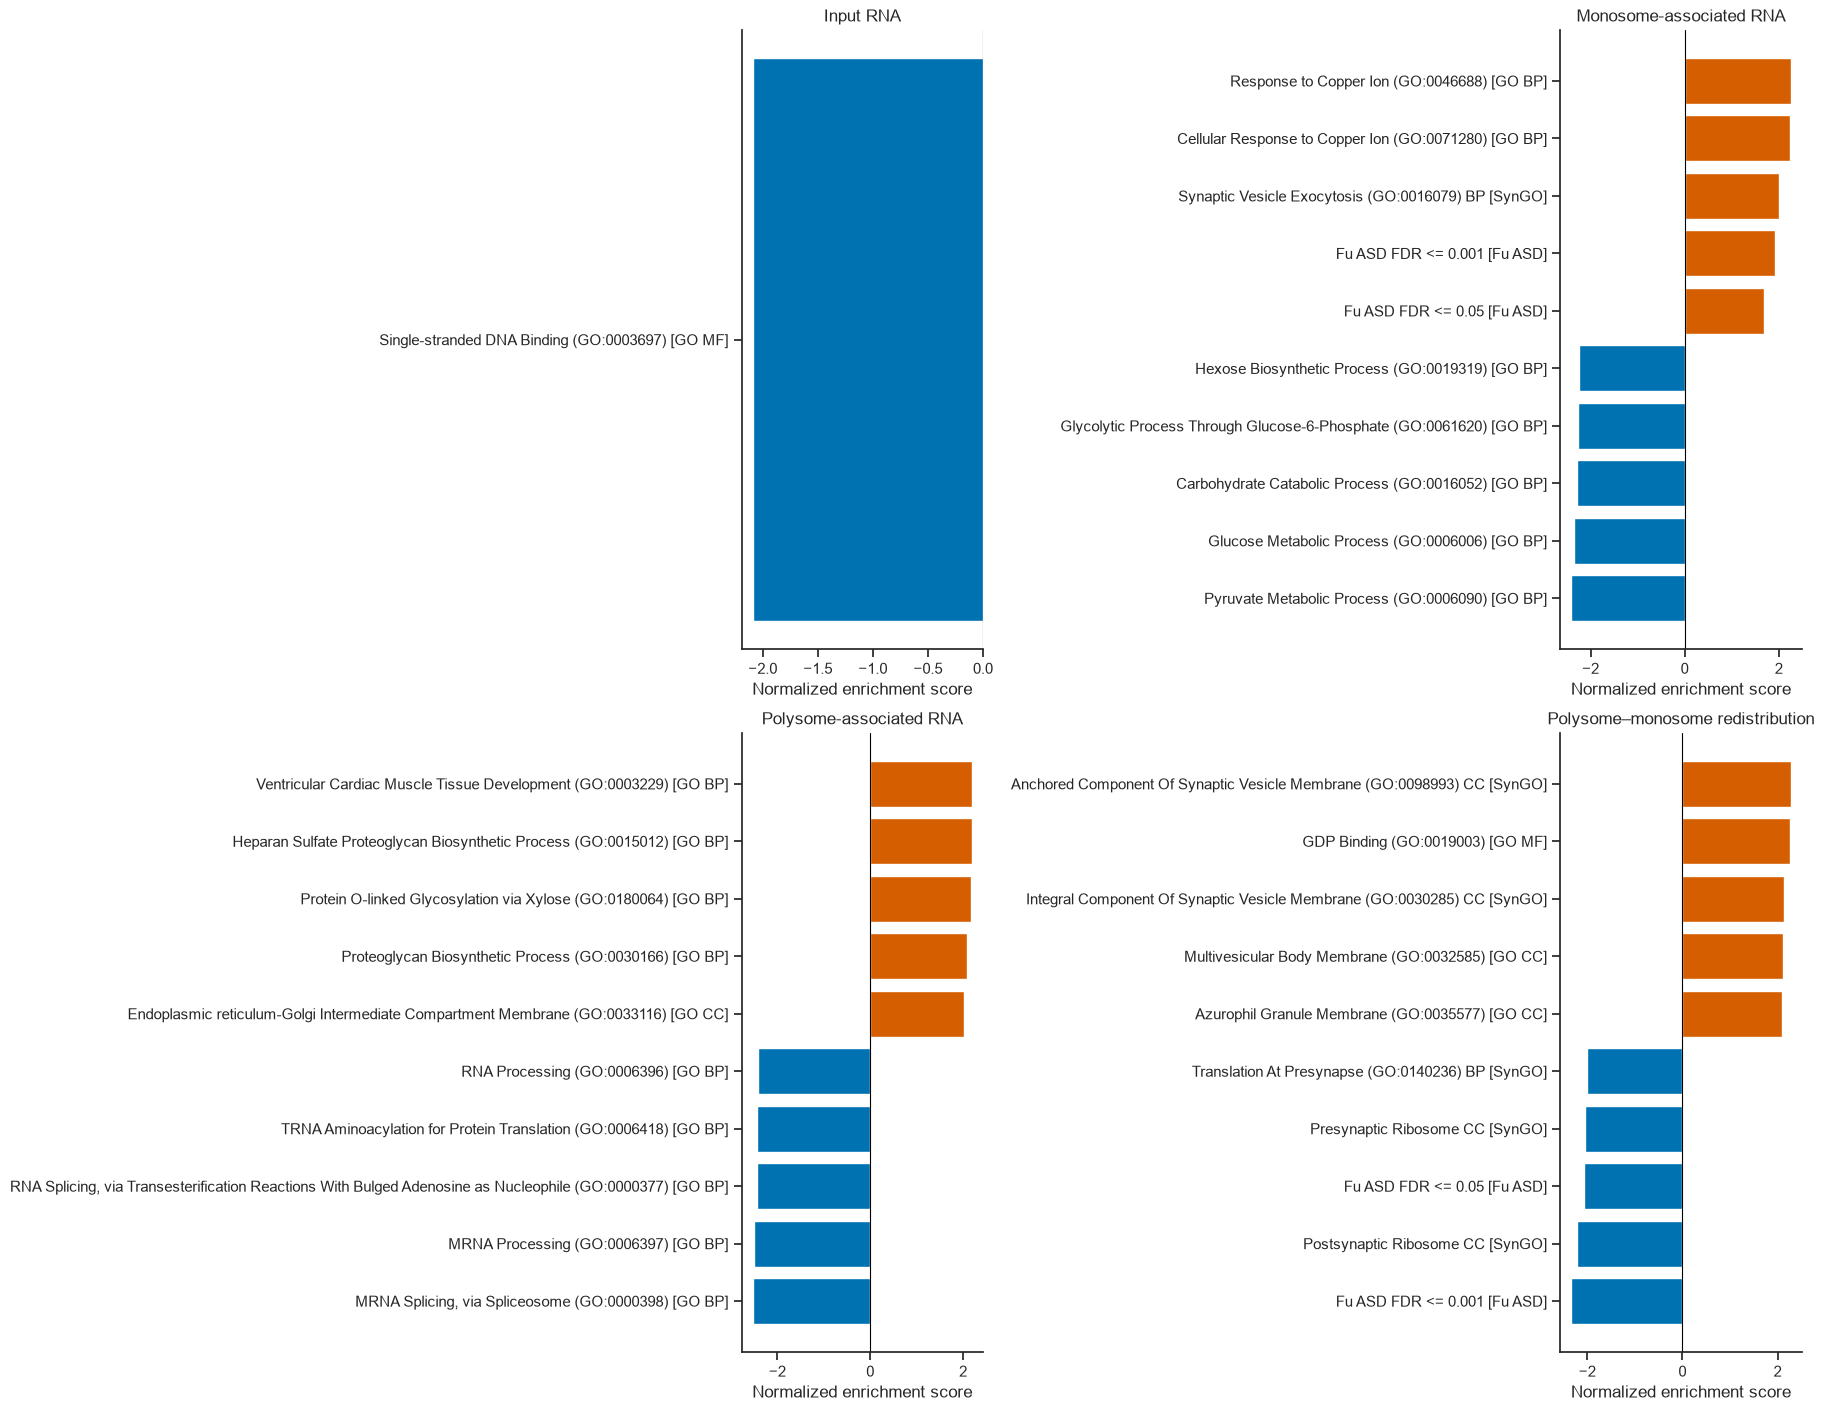

In [28]:
# Plot up to five ranked terms in each direction per analysis.


def select_plot_terms(table: pd.DataFrame, value: str):
    selected = table.loc[table['adjustedPValue'].lt(ALPHA)].copy()
    selected = selected.sort_values(
        ['analysis', 'direction', 'adjustedPValue', 'pValue']
    )
    selected = selected.groupby(
        ['analysis', 'direction'],
        observed = True,
    ).head(5)
    selected['displayTerm'] = (
        selected['term']
        + ' ['
        + selected['collection'].map(COLLECTION_LABELS)
        + ']'
    )
    selected['plotValue'] = selected[value]
    return selected


ranked_plot = select_plot_terms(
    ranked_enrichment,
    'normalizedEnrichmentScore',
)
figure, axes = plt.subplots(2, 2, figsize = (18, 14), constrained_layout = True)

for ax, analysis in zip(axes.flat, ANALYSES):
    selected = ranked_plot.loc[ranked_plot['analysis'].eq(analysis)]
    selected = selected.sort_values('plotValue')
    if selected.empty:
        ax.text(0.5, 0.5, 'No terms at FDR < 0.05', ha = 'center', va = 'center')
        ax.set_axis_off()
        continue
    colors = np.where(selected['plotValue'].gt(0), '#D55E00', '#0072B2')
    ax.barh(selected['displayTerm'], selected['plotValue'], color = colors)
    ax.axvline(0, color = 'black', linewidth = 0.8)
    ax.set(
        xlabel = 'Normalized enrichment score',
        ylabel = '',
        title = ANALYSIS_LABELS[analysis],
    )

sns.despine()
plt.show()


In [29]:
# Test whether FDR selection depends on effective length or abundance.


def load_effective_lengths(
    specifications: list[tuple[str, str]],
    gene_ids: pd.Index,
):
    matrices = []
    for folder, prefix in specifications:
        path = DATA_DIR / folder / 'salmon.merged.gene_lengths.tsv'
        table = pd.read_csv(path, sep = '\t').set_index('gene_id')
        columns = [f'{prefix}{sample_id}' for sample_id in sample_ids]
        missing = gene_ids.difference(table.index)
        if not missing.empty:
            raise ValueError(f'{folder} is missing {len(missing)} modeled genes.')
        values = table.loc[gene_ids, columns]
        matrices.append(values.to_numpy(dtype = 'float64'))

    combined = np.concatenate(matrices, axis = 1)
    if not np.isfinite(combined).all() or (combined <= 0).any():
        raise ValueError('Effective gene lengths must be finite and positive.')
    return pd.Series(
        np.median(combined, axis = 1),
        index = gene_ids,
        name = 'effectiveLength',
    )


length_sources = {
    'input': [('Input', 'input')],
    'monosome': [('Monosome', 'mono')],
    'polysome': [('Polysome', 'poly')],
    'redistribution': [('Monosome', 'mono'), ('Polysome', 'poly')],
}
bias_records = []

for analysis, table in analysis_tables.items():
    lengths = load_effective_lengths(
        length_sources[analysis],
        pd.Index(table['geneId']),
    )
    model_table = table.copy()
    model_table['effectiveLength'] = model_table['geneId'].map(lengths)
    model_table['selected'] = model_table['adjustedPValue'].lt(ALPHA).astype('int64')
    predictors = pd.DataFrame({
        'logEffectiveLength': np.log(model_table['effectiveLength']),
        'logBaseMean': np.log1p(model_table['baseMean']),
    }, index = model_table.index)
    predictors = (predictors - predictors.mean()) / predictors.std(ddof = 0)
    predictors = sm.add_constant(predictors, has_constant = 'add')
    fit = sm.GLM(
        model_table['selected'],
        predictors,
        family = sm.families.Binomial(),
    ).fit()

    for covariate in ('logEffectiveLength', 'logBaseMean'):
        bias_records.append({
            'analysis': analysis,
            'covariate': covariate,
            'coefficient': fit.params[covariate],
            'oddsRatio': np.exp(fit.params[covariate]),
            'standardError': fit.bse[covariate],
            'pValue': fit.pvalues[covariate],
            'selectedGenes': int(model_table['selected'].sum()),
            'universeGenes': len(model_table),
        })

selection_bias = pd.DataFrame(bias_records)
display(selection_bias)


,analysis,covariate,coefficient,oddsRatio,standardError,pValue,selectedGenes,universeGenes
0,input,logEffectiveLength,-0.083314,0.920063,0.061698,1.769077e-01,253,17762
1,input,logBaseMean,-0.332396,0.717203,0.063085,1.371240e-07,253,17762
2,monosome,logEffectiveLength,-0.151900,0.859074,0.074694,4.198940e-02,165,17741
3,monosome,logBaseMean,-0.058577,0.943105,0.076296,4.426253e-01,165,17741
4,polysome,logEffectiveLength,-0.115144,0.891238,0.072559,1.125323e-01,177,17578
5,polysome,logBaseMean,-0.204787,0.814821,0.073704,5.461099e-03,177,17578
6,redistribution,logEffectiveLength,-0.144233,0.865686,0.217435,5.071130e-01,20,17160
7,redistribution,logBaseMean,0.237205,1.267702,0.228870,3.000062e-01,20,17160


In [30]:
# Run direction-specific ORA within each tested and mapped universe.
# BH adjustment is performed within each analysis, collection, and direction.


def run_ora(
    analysis: str,
    table: pd.DataFrame,
    collection: str,
    terms: dict[str, list[str]],
    direction: str,
):
    universe = set(table.index)
    if direction == 'positive':
        selected = set(table.index[
            table['adjustedPValue'].lt(ALPHA)
            & table['log2FoldChange'].gt(0)
        ])
    else:
        selected = set(table.index[
            table['adjustedPValue'].lt(ALPHA)
            & table['log2FoldChange'].lt(0)
        ])

    M = len(universe)
    N = len(selected)
    records = []

    for term, genes in terms.items():
        members = universe.intersection(genes)
        n = len(members)
        if not MIN_SET_SIZE <= n <= MAX_SET_SIZE:
            continue
        overlap = sorted(selected.intersection(members))
        k = len(overlap)
        expected = N * n / M
        records.append({
            'analysis': analysis,
            'collection': collection,
            'term': term,
            'direction': direction,
            'directionLabel': DIRECTION_LABELS[(analysis, direction)],
            'universeGenes': M,
            'selectedGenes': N,
            'geneSetSize': n,
            'overlapGenesCount': k,
            'expectedOverlap': expected,
            'enrichmentRatio': k / expected if expected else np.nan,
            'pValue': hypergeom.sf(k - 1, M, n, N),
            'overlapGenes': ';'.join(overlap),
        })

    frame = pd.DataFrame(records)
    if frame.empty:
        raise ValueError(f'No eligible terms for {analysis}, {collection}.')
    frame['adjustedPValue'] = multipletests(
        frame['pValue'],
        method = 'fdr_bh',
    )[1]
    return frame


ora_tables = []

for analysis, table in analysis_tables.items():
    for collection, terms in gene_sets.items():
        for direction in ('positive', 'negative'):
            ora_tables.append(
                run_ora(analysis, table, collection, terms, direction)
            )

overrepresentation = pd.concat(ora_tables, ignore_index = True)
overrepresentation = overrepresentation.sort_values(
    ['analysis', 'collection', 'direction', 'adjustedPValue', 'pValue']
)
ora_summary = overrepresentation.groupby(
    ['analysis', 'collection', 'direction'],
    observed = True,
).agg(
    selectedGenes = ('selectedGenes', 'first'),
    testedTerms = ('term', 'size'),
    fdrTerms = ('adjustedPValue', lambda values: values.lt(ALPHA).sum()),
).reset_index()
display(ora_summary)


,analysis,collection,direction,selectedGenes,testedTerms,fdrTerms
0,input,fuAsd,negative,143,2,0
1,input,fuAsd,positive,110,2,0
2,input,goBiologicalProcess,negative,143,3350,15
3,input,goBiologicalProcess,positive,110,3350,0
4,input,goCellularComponent,negative,143,314,0
5,input,goCellularComponent,positive,110,314,0
6,input,goMolecularFunction,negative,143,665,1
7,input,goMolecularFunction,positive,110,665,0
8,input,synGO,negative,143,78,0
9,input,synGO,positive,110,78,0


In [31]:
# Inspect ORA terms with multiple contributing genes.

leading_ora = overrepresentation.loc[
    overrepresentation['adjustedPValue'].lt(ALPHA)
    & overrepresentation['overlapGenesCount'].ge(3)
].sort_values(
    ['analysis', 'adjustedPValue', 'pValue'],
)

for analysis in ANALYSES:
    print(f'{analysis.title()} leading ORA terms')
    display(leading_ora.loc[leading_ora['analysis'].eq(analysis)].head(20))


Input leading ORA terms


,analysis,collection,term,direction,directionLabel,universeGenes,selectedGenes,geneSetSize,overlapGenesCount,expectedOverlap,enrichmentRatio,pValue,overlapGenes,adjustedPValue
4808,input,goBiologicalProcess,Nervous System Development (GO:0007399),negative,Lower in ASD,17762,143,500,18,4.025448,4.471552,1.127017e-07,CBLN1;CNTN6;DMBX1;EMX2;FGF19;GDNF;GSX1;HES1;LD...,0.000378
6113,input,goBiologicalProcess,Regulation of Osteoclast Differentiation (GO:0...,negative,Lower in ASD,17762,143,33,5,0.265680,18.819665,6.241310e-06,CARTPT;DLK1;POU4F1;POU4F2;TMEM178A,0.010454
8141,input,goMolecularFunction,"DNA-binding Transcription Activator Activity, ...",negative,Lower in ASD,17762,143,280,11,2.254251,4.879670,1.684936e-05,LEF1;MECOM;PHOX2A;PHOX2B;POU4F1;POU4F2;SIX1;TB...,0.011205
5082,input,goBiologicalProcess,Positive Regulation of Cell Population Prolife...,negative,Lower in ASD,17762,143,380,13,3.059340,4.249282,1.248084e-05,BMP6;CLDN5;FGF19;GDNF;GPER1;HES1;LEF1;MAPK15;S...,0.013937
4822,input,goBiologicalProcess,Neuron Differentiation (GO:0030182),negative,Lower in ASD,17762,143,182,9,1.465263,6.142242,1.676485e-05,DRGX;EMX2;GSX1;IRX1;LMX1B;PCSK9;PHOX2A;PHOX2B;...,0.014041
4015,input,goBiologicalProcess,Generation of Neurons (GO:0048699),negative,Lower in ASD,17762,143,188,9,1.513568,5.946213,2.169330e-05,EMX2;GSX1;IRX1;LMX1B;MDGA1;PCSK9;PHOX2B;POU4F2...,0.014535
4072,input,goBiologicalProcess,Heart Morphogenesis (GO:0003007),negative,Lower in ASD,17762,143,51,5,0.410596,12.177430,5.498963e-05,HES1;TBX2;TBX20;TBX3;TH,0.024636
6085,input,goBiologicalProcess,Regulation of Neuron Apoptotic Process (GO:004...,negative,Lower in ASD,17762,143,121,7,0.974158,7.185690,5.561633e-05,CFLAR;GDNF;PCSK9;POU4F1;SIX1;TFAP2A;TFAP2B,0.024636
3993,input,goBiologicalProcess,Forelimb Morphogenesis (GO:0035136),negative,Lower in ASD,17762,143,10,3,0.080509,37.262937,5.883204e-05,TBX3;TFAP2A;TFAP2B,0.024636
3865,input,goBiologicalProcess,Embryonic Heart Tube Development (GO:0035050),negative,Lower in ASD,17762,143,11,3,0.088560,33.875397,8.041696e-05,HES1;TBX2;TBX20,0.029933


Monosome leading ORA terms


,analysis,collection,term,direction,directionLabel,universeGenes,selectedGenes,geneSetSize,overlapGenesCount,expectedOverlap,enrichmentRatio,pValue,overlapGenes,adjustedPValue
14916,monosome,goBiologicalProcess,Regulation of Osteoclast Differentiation (GO:0...,negative,Lower monosome-associated abundance in ASD,17741,91,34,5,0.174398,28.670006,7.861935e-07,CARTPT;DLK1;POU4F1;POU4F2;TMEM178A,0.002627
9165,monosome,goBiologicalProcess,Cellular Response to Zinc Ion (GO:0071294),positive,Higher monosome-associated abundance in ASD,17741,74,10,3,0.041711,71.922973,8.185999e-06,MT1F;MT1G;MT1X,0.012501
9089,monosome,goBiologicalProcess,Cellular Response to Cadmium Ion (GO:0071276),positive,Higher monosome-associated abundance in ASD,17741,74,11,3,0.045882,65.384521,1.122200e-05,MT1F;MT1G;MT1X,0.012501
9094,monosome,goBiologicalProcess,Cellular Response to Copper Ion (GO:0071280),positive,Higher monosome-associated abundance in ASD,17741,74,11,3,0.045882,65.384521,1.122200e-05,MT1F;MT1G;MT1X,0.012501
13619,monosome,goBiologicalProcess,Nervous System Development (GO:0007399),negative,Lower monosome-associated abundance in ASD,17741,91,497,12,2.549293,4.707188,8.661123e-06,CBLN1;DMBX1;FGF19;GSX1;HES1;NHLH2;PCDHB5;PHOX2...,0.014473
11826,monosome,goBiologicalProcess,Response to Copper Ion (GO:0046688),positive,Higher monosome-associated abundance in ASD,17741,74,13,3,0.054225,55.325364,1.933500e-05,MT1F;MT1G;MT1X,0.016154
14090,monosome,goBiologicalProcess,Positive Regulation of Myeloid Leukocyte Diffe...,negative,Lower monosome-associated abundance in ASD,17741,91,31,4,0.159010,25.155619,1.833103e-05,DLK1;LEF1;POU4F1;POU4F2,0.020421
14118,monosome,goBiologicalProcess,Positive Regulation of Osteoclast Differentiat...,negative,Lower monosome-associated abundance in ASD,17741,91,13,3,0.066682,44.989856,3.597531e-05,DLK1;POU4F1;POU4F2,0.025092
13633,monosome,goBiologicalProcess,Neuron Differentiation (GO:0030182),negative,Lower monosome-associated abundance in ASD,17741,91,179,7,0.918156,7.623979,3.754078e-05,DRGX;GSX1;ID3;LMX1B;PHOX2A;PHOX2B;POU4F2,0.025092
13930,monosome,goBiologicalProcess,Positive Regulation of DNA Binding (GO:0043388),negative,Lower monosome-associated abundance in ASD,17741,91,16,3,0.082070,36.554258,6.965955e-05,HES1;POU4F1;POU4F2,0.038800


Polysome leading ORA terms


,analysis,collection,term,direction,directionLabel,universeGenes,selectedGenes,geneSetSize,overlapGenesCount,expectedOverlap,enrichmentRatio,pValue,overlapGenes,adjustedPValue
25752,polysome,goMolecularFunction,"DNA-binding Transcription Repressor Activity, ...",negative,Lower polysome-associated abundance in ASD,17578,108,205,8,1.259529,6.351581,0.000039,FOXA2;HES1;MSX2;NFATC4;POU4F1;POU4F2;TBX2;TFAP2A,0.016031
25750,polysome,goMolecularFunction,"DNA-binding Transcription Activator Activity, ...",negative,Lower polysome-associated abundance in ASD,17578,108,274,9,1.683468,5.346107,0.000049,FOXA2;LEF1;MECOM;PHOX2A;PHOX2B;POU4F1;POU4F2;T...,0.016031
25105,polysome,goMolecularFunction,E-box Binding (GO:0070888),positive,Higher polysome-associated abundance in ASD,17578,69,44,4,0.172716,23.159420,0.000026,BHLHE22;NEUROD4;NEUROG1;OLIG3,0.017330
21453,polysome,goBiologicalProcess,Dopaminergic Neuron Differentiation (GO:0071542),negative,Lower polysome-associated abundance in ASD,17578,108,21,4,0.129025,31.001764,0.000007,FOXA2;LMX1B;PHOX2A;PHOX2B,0.024906
25089,polysome,goMolecularFunction,"DNA-binding Transcription Activator Activity, ...",positive,Higher polysome-associated abundance in ASD,17578,69,274,7,1.075549,6.508304,0.000098,ESRRB;ETV1;HOXD3;HOXD8;LITAF;PAX6;SOX14,0.032367


Redistribution leading ORA terms


,analysis,collection,term,direction,directionLabel,universeGenes,selectedGenes,geneSetSize,overlapGenesCount,expectedOverlap,enrichmentRatio,pValue,overlapGenes,adjustedPValue


In [32]:
# Quantify agreement between ranked enrichment and ORA.

concordance_records = []

for analysis in ANALYSES:
    for collection in COLLECTION_LABELS:
        for direction in ('positive', 'negative'):
            ranked_terms = set(ranked_enrichment.loc[
                ranked_enrichment['analysis'].eq(analysis)
                & ranked_enrichment['collection'].eq(collection)
                & ranked_enrichment['direction'].eq(direction)
                & ranked_enrichment['adjustedPValue'].lt(ALPHA),
                'term',
            ])
            ora_terms = set(overrepresentation.loc[
                overrepresentation['analysis'].eq(analysis)
                & overrepresentation['collection'].eq(collection)
                & overrepresentation['direction'].eq(direction)
                & overrepresentation['adjustedPValue'].lt(ALPHA),
                'term',
            ])
            shared = sorted(ranked_terms.intersection(ora_terms))
            concordance_records.append({
                'analysis': analysis,
                'collection': collection,
                'direction': direction,
                'rankedFdrTerms': len(ranked_terms),
                'oraFdrTerms': len(ora_terms),
                'sharedFdrTerms': len(shared),
                'sharedTerms': ';'.join(shared),
            })

enrichment_concordance = pd.DataFrame(concordance_records)
display(enrichment_concordance.loc[
    enrichment_concordance['sharedFdrTerms'].gt(0)
])


,analysis,collection,direction,rankedFdrTerms,oraFdrTerms,sharedFdrTerms,sharedTerms
10,monosome,goBiologicalProcess,positive,2,5,2,Cellular Response to Copper Ion (GO:0071280);R...
11,monosome,goBiologicalProcess,negative,44,6,1,Regulation of Osteoclast Differentiation (GO:0...
21,polysome,goBiologicalProcess,negative,106,1,1,Dopaminergic Neuron Differentiation (GO:0071542)


In [33]:
# Save complete enrichment results and analysis diagnostics.

ranked_enrichment.to_csv(
    RESULTS_DIR / 'rankedEnrichment.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
overrepresentation.to_csv(
    RESULTS_DIR / 'overrepresentationAnalysis.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
mapping_summary.to_csv(
    RESULTS_DIR / 'enrichmentMappingSummary.tsv',
    sep = '\t',
    index = False,
)
collection_summary.to_csv(
    RESULTS_DIR / 'enrichmentCollectionSummary.tsv',
    sep = '\t',
    index = False,
)
selection_bias.to_csv(
    RESULTS_DIR / 'selectionBiasDiagnostics.tsv',
    sep = '\t',
    index = False,
)
enrichment_concordance.to_csv(
    RESULTS_DIR / 'enrichmentConcordance.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
ranked_timing.to_csv(
    RESULTS_DIR / 'rankedEnrichmentTiming.tsv',
    sep = '\t',
    index = False,
)
